In [1]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout, Bidirectional
from sklearn.utils import class_weight
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

import joblib

In [2]:
X_train_ped,X_test_ped,y_train, y_test = joblib.load(
    r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\model\split.pkl"
)

In [3]:
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights))

print(class_weights)


{0: np.float64(0.8928547556981485), 1: np.float64(0.6923216460649407), 2: np.float64(2.2957806994929966)}


In [4]:
model =tf.keras.Sequential([
    tf.keras.layers.Embedding(10000,128,input_length=300),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128,return_state=False)),
    tf.keras.layers.Dense(62,activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(3,activation="softmax")
])

c:\Users\akash\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
print("X_train:", X_train_ped.dtype)
print("X_test :", X_test_ped.dtype)
print("y_train:", y_train.dtype)
print("y_test :", y_test.dtype)

X_train: int32
X_test : int32
y_train: object
y_test : object


In [7]:
y_train = y_train.astype("int32")
y_test = y_test.astype("int32")

In [8]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)


history = model.fit(
    X_train_ped,
    y_train,

    validation_data=(
        X_test_ped,
        y_test
    ),

    epochs=10,
    batch_size=32,
 class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/10
835/835 ━━━━━━━━━━━━━━━━━━━━ 203s 238ms/step - accuracy: 0.7421 - loss: 0.6916 - val_accuracy: 0.7810 - val_loss: 0.5389
Epoch 2/10
835/835 ━━━━━━━━━━━━━━━━━━━━ 745s 893ms/step - accuracy: 0.8091 - loss: 0.5326 - val_accuracy: 0.8040 - val_loss: 0.5173
Epoch 3/10
835/835 ━━━━━━━━━━━━━━━━━━━━ 267s 267ms/step - accuracy: 0.8406 - loss: 0.4587 - val_accuracy: 0.7635 - val_loss: 0.5865
Epoch 4/10
835/835 ━━━━━━━━━━━━━━━━━━━━ 224s 269ms/step - accuracy: 0.8616 - loss: 0.3938 - val_accuracy: 0.7957 - val_loss: 0.5430


In [14]:
test_loss, test_acc = model.evaluate(
    X_test_ped,
    y_test
)

print("Test Accuracy:", test_acc)

209/209 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.8040 - loss: 0.5173
Test Accuracy: 0.8040419220924377


In [15]:

y_prob = model.predict(X_test_ped)

y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_test, y_pred))

209/209 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      2543
           1       0.92      0.81      0.86      3198
           2       0.47      0.62      0.53       939

    accuracy                           0.80      6680
   macro avg       0.74      0.76      0.75      6680
weighted avg       0.83      0.80      0.81      6680



In [16]:

print(confusion_matrix(y_test, y_pred))

[[2190   84  269]
 [ 200 2599  399]
 [ 201  156  582]]


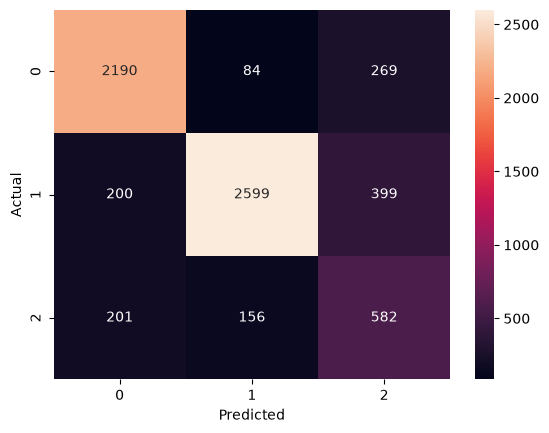

In [12]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig(r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\report\confuseion_matrix_plt\confuseion_matrix.png")
plt.show()

In [17]:
joblib.dump(model,r"C:\Users\akash\OneDrive\Documents\nlp project\Sentiment Analysis project using NLP + RNN + LSTM,\model\LSTM_MODEL.pkl")

['C:\\Users\\akash\\OneDrive\\Documents\\nlp project\\Sentiment Analysis project using NLP + RNN + LSTM,\\model\\LSTM_MODEL.pkl']